
Dataset SNAP « GitHub Social Network » (MUSAE, Rozemberczki et al.), generato a giugno 2019.
Nodi = sviluppatori che hanno messo una stella ad almeno 10 repository; archi = follow reciproco (non orientato).
Label ml_target: 0 = sviluppatore web, 1 = sviluppatore machine learning.

Ce notebook :
1. carica i tre file e ne verifica la coerenza; ;
2. construit le graphe `G` et compare ses statistiques à celles annoncées par SNAP ;
3. calcola le metriche globali e le distribuzioni (gradi, classi, omofilia) ;
4. costruisce i sottografi utilizzati nei capitoli successivi  (`G_web`, `G_ml`, `G_core`) ;
5. salva i grafi, la tabella dei nodi, le tabelle LaTeX e le figure.

In [3]:
import json
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)

# Recherche du dossier du projet (celui qui contient data/raw/git_web_ml), quel que soit le dossier de lancement
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "data" / "raw" / "git_web_ml").is_dir())
RAW = ROOT / "data" / "raw" / "git_web_ml"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "1_DATASET_ANALYSIS" / "figures"
TAB = ROOT / "1_DATASET_ANALYSIS" / "tables"
for d in (PROC, FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

print("Projet :", ROOT)
print("networkx", nx.__version__, "| pandas", pd.__version__)

# Style des figures (rapport LaTeX, largeur 0,9\textwidth) ; textes des figures et tableaux en italien
WEB_COL, ML_COL = "#2a78d6", "#eb6834"   # web = bleu, ML = orange (fixe dans tout le rapport)
CLASS_COL = {0: WEB_COL, 1: ML_COL}
CLASS_NAME = {0: "Web", 1: "Machine learning"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.pdf")
    fig.savefig(FIG / f"{name}.png")
    print("Figure enregistrée :", name)

Projet : C:\Users\toyem\Desktop\MAGISTRALE\2° ANNO\DATA SCIENCE\DATA_SCIENCE_PROJECT\2_SOCIAL_NETWORK_ANALYSIS
networkx 3.6.1 | pandas 3.1.1


## 1. caricamento dei file

In [4]:
edges = pd.read_csv(RAW / "musae_git_edges.csv")
target = pd.read_csv(RAW / "musae_git_target.csv")
with open(RAW / "musae_git_features.json", encoding="utf-8") as f:
    features = json.load(f)

print("edges   :", edges.shape, list(edges.columns))
print("target  :", target.shape, list(target.columns))
print("features:", len(features), "nœuds")
display(edges.head(), target.head())
print(edges.dtypes, target.dtypes, sep="\n")

edges   : (289003, 2) ['id_1', 'id_2']
target  : (37700, 3) ['id', 'name', 'ml_target']
features: 37700 nœuds


,id_1,id_2
0,0,23977
1,1,34526
2,1,2370
3,1,14683
4,1,29982


,id,name,ml_target
0,0,Eiryyy,0
1,1,shawflying,0
2,2,JpMCarrilho,1
3,3,SuhwanCha,0
4,4,sunilangadi2,1


id_1    int64
id_2    int64
dtype: object
id           int64
name           str
ml_target    int64
dtype: object


## 2. Controlli di coerenza

Si verifica: valori mancanti, identificatori contigui, corrispondenza tra i tre file, autoanelli (loop), archi duplicati (inclusi u–v / v–u, essendo il grafo non orientato), nodi isolati, nomi duplicati.

In [9]:
checks = {}
checks["NaN dans edges"] = int(edges.isna().sum().sum())
checks["NaN dans target"] = int(target.isna().sum().sum())

ids_target = set(target["id"])
ids_edges = set(edges["id_1"]) | set(edges["id_2"])
ids_feat = {int(k) for k in features}
n = len(target)
checks["id target contigus 0..n-1"] = ids_target == set(range(n))
checks["id uniques dans target"] = target["id"].is_unique
checks["id edges absents de target"] = len(ids_edges - ids_target)
checks["id target sans arête (isolés)"] = len(ids_target - ids_edges)
checks["id features = id target"] = ids_feat == ids_target

checks["boucles (u = v)"] = int((edges["id_1"] == edges["id_2"]).sum())
und = pd.DataFrame({"u": edges[["id_1", "id_2"]].min(axis=1), "v": edges[["id_1", "id_2"]].max(axis=1)})
checks["arêtes en double exact (u, v)"] = int(edges.duplicated().sum())
checks["arêtes stockées dans les 2 sens (u, v)+(v, u)"] = int(und.duplicated().sum() - edges.duplicated().sum())

checks["valeurs de ml_target"] = sorted(target["ml_target"].unique().tolist())
checks["noms en double"] = int(target["name"].duplicated().sum())

pd.Series(checks, name="résultat").to_frame()

,résultat
NaN dans edges,0
NaN dans target,0
id target contigus 0..n-1,True
id uniques dans target,True
id edges absents de target,0
id target sans arête (isolés),0
id features = id target,True
boucles (u = v),0
"arêtes en double exact (u, v)",0
"arêtes stockées dans les 2 sens (u, v)+(v, u)",0


In [10]:
# Détail des noms en double (s'il y en a) : même pseudo pour deux id différents ?
dup = target[target["name"].duplicated(keep=False)].sort_values("name")
print(len(dup), "lignes concernées")
dup.head(20)

0 lignes concernées


,id,name,ml_target


## 3. Costruzione del grafo `G`

In [11]:
G = nx.Graph()
G.add_nodes_from(target["id"])          # inclut d'éventuels nœuds isolés
G.add_edges_from(und.drop_duplicates().itertuples(index=False, name=None))
G.remove_edges_from(nx.selfloop_edges(G))

attrs = target.set_index("id")
nx.set_node_attributes(G, attrs["name"].to_dict(), "name")
nx.set_node_attributes(G, attrs["ml_target"].to_dict(), "ml_target")
nx.set_node_attributes(G, {int(k): len(v) for k, v in features.items()}, "n_features")

t0 = time.time()
official = {"Nodi": 37_700, "Archi": 289_003, "Densità": 0.001, "Transitività": 0.013}
ours = {"Nodi": G.number_of_nodes(), "Archi": G.number_of_edges(),
        "Densità": nx.density(G), "Transitività": nx.transitivity(G)}
cmp = pd.DataFrame({"SNAP": official, "Calcolato": ours})
print(f"({time.time() - t0:.1f} s)")
cmp

(10.7 s)


,SNAP,Calcolato
Nodi,37700.000,37700.000000
Archi,289003.000,289003.000000
Densità,0.001,0.000407
Transitività,0.013,0.012357


## 4. Distribuzione delle classi e attributi dei nodi

In [ ]:
cls = target["ml_target"].map(CLASS_NAME).value_counts().to_frame("nœuds")
cls["%"] = (100 * cls["nœuds"] / cls["nœuds"].sum()).round(1)
display(cls)

nfeat = pd.Series({int(k): len(v) for k, v in features.items()}).sort_index()
all_feat = {x for v in features.values() for x in v}
print(f"Features distinte : {len(all_feat)} (indices {min(all_feat)}–{max(all_feat)})")
print("Features per nodi :", nfeat.describe().round(2).to_dict())

,nœuds,%
ml_target,,
Web,27961,74.2
Machine learning,9739,25.8


Features distinctes : 4005 (indices 0–4004)
Features par nœud : {'count': 37700.0, 'mean': 18.31, 'std': 3.6, 'min': 8.0, '25%': 16.0, '50%': 18.0, '75%': 20.0, 'max': 42.0}


Figure enregistrée : features_per_nodo


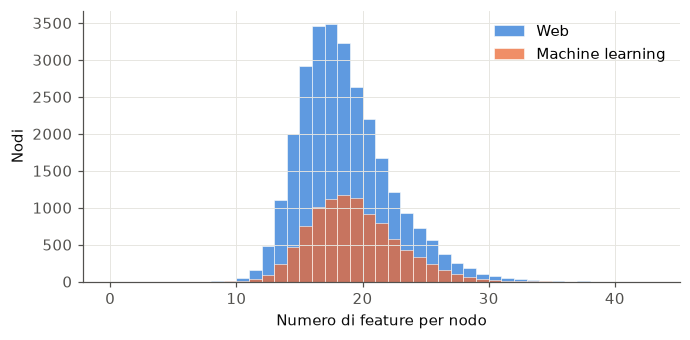

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(0, nfeat.max() + 2)
for c in (0, 1):
    ax.hist(nfeat[target.set_index("id")["ml_target"] == c], bins=bins, alpha=0.75,
            color=CLASS_COL[c], label=CLASS_NAME[c], edgecolor="#fcfcfb", linewidth=0.5)
ax.set_xlabel("Numero di feature per nodo")
ax.set_ylabel("Nodi")
ax.legend(frameon=False)
save_fig(fig, "features_per_nodo")
plt.show()

## 5. Metriche globali del grafo

In [14]:
def avg_shortest_path_sample(H, n_sources=200, seed=SEED):
    """Longueur moyenne des plus courts chemins estimée par BFS depuis n_sources nœuds tirés au hasard
    (le calcul exact sur 37 700 nœuds demanderait 37 700 BFS)."""
    nodes = list(H.nodes())
    r = np.random.default_rng(seed)
    src = r.choice(nodes, size=min(n_sources, len(nodes)), replace=False)
    tot, cnt, ecc = 0, 0, 0
    for s in src:
        d = nx.single_source_shortest_path_length(H, s)
        tot += sum(d.values()); cnt += len(d) - 1; ecc = max(ecc, max(d.values()))
    return tot / cnt, ecc

def graph_metrics(H, name, exact_paths=False):
    t0 = time.time()
    exact_paths = exact_paths and H.number_of_nodes() <= 3000   # au-delà, estimation par échantillonnage
    deg = np.array([d for _, d in H.degree()])
    comps = list(nx.connected_components(H))
    lcc = H.subgraph(max(comps, key=len))
    m = {
        "Grafo": name,
        "Nodi": H.number_of_nodes(),
        "Archi": H.number_of_edges(),
        "Densità": nx.density(H),
        "Grado medio": deg.mean(),
        "Grado max": deg.max(),
        "Componenti": len(comps),
        "Nodi LCC (%)": 100 * lcc.number_of_nodes() / H.number_of_nodes(),
        "Transitività": nx.transitivity(H),
        "Clustering medio": nx.average_clustering(H),
        "Assortatività grado": nx.degree_assortativity_coefficient(H),
    }
    if len({d["ml_target"] for _, d in H.nodes(data=True)}) > 1:
        m["Assortatività ml_target"] = nx.attribute_assortativity_coefficient(H, "ml_target")
    else:
        m["Assortatività ml_target"] = np.nan
    if exact_paths:
        m["Cammino medio (LCC)"] = nx.average_shortest_path_length(lcc)
        m["Diametro (LCC)"] = nx.diameter(lcc)
    else:
        m["Cammino medio (LCC)"], m["Diametro (LCC)"] = avg_shortest_path_sample(lcc)
        # borne inférieure du diamètre (2-sweep) : plus fiable que l'excentricité des sources tirées
        m["Diametro (LCC)"] = max(m["Diametro (LCC)"], nx.approximation.diameter(lcc, seed=SEED))
    print(f"{name}: {time.time() - t0:.1f} s")
    return m

metrics_G = graph_metrics(G, "G")
pd.Series(metrics_G).to_frame("G")

G: 64.8 s


,G
Grafo,G
Nodi,37700
Archi,289003
Densità,0.000407
Grado medio,15.331724
Grado max,9458
Componenti,1
Nodi LCC (%),100.0
Transitività,0.012357
Clustering medio,0.167537


Nota per il rapporto: su G, il cammino medio è stimato (BFS da 200 sorgenti) e il diametro è una soglia inferiore (algoritmo 2-sweep). Sui sottografi piccoli, essi sono esatti.

In [15]:
comp_sizes = pd.Series([len(c) for c in nx.connected_components(G)]).value_counts().sort_index()
comp_sizes.rename_axis("taille composante").to_frame("nombre")

,nombre
taille composante,
37700,1


## 6. Distribuzione dei gradi

In [16]:
deg = pd.Series(dict(G.degree()), name="degree")
cls_s = target.set_index("id")["ml_target"]
display(deg.groupby(cls_s).describe().rename(index=CLASS_NAME).round(2))
top = deg.sort_values(ascending=False).head(10).to_frame()
top["name"] = top.index.map(attrs["name"]); top["classe"] = top.index.map(cls_s).map(CLASS_NAME)
top

,count,mean,std,min,25%,50%,75%,max
ml_target,,,,,,,,
Web,27961.0,17.67,92.77,1.0,3.0,6.0,15.0,9458.0
Machine learning,9739.0,8.63,22.25,1.0,2.0,4.0,9.0,967.0


,degree,name,classe
31890,9458,dalinhuang99,Web
27803,7085,nfultz,Web
35773,3324,addyosmani,Web
19222,2958,Bunlong,Web
13638,2468,gabrielpconceicao,Web
36652,2343,rfthusn,Web
18163,1924,nelsonic,Web
9051,1797,getify,Web
35008,1571,mdo,Web
10001,1568,ronenhamias,Web


Figure enregistrée : distribuzione_gradi


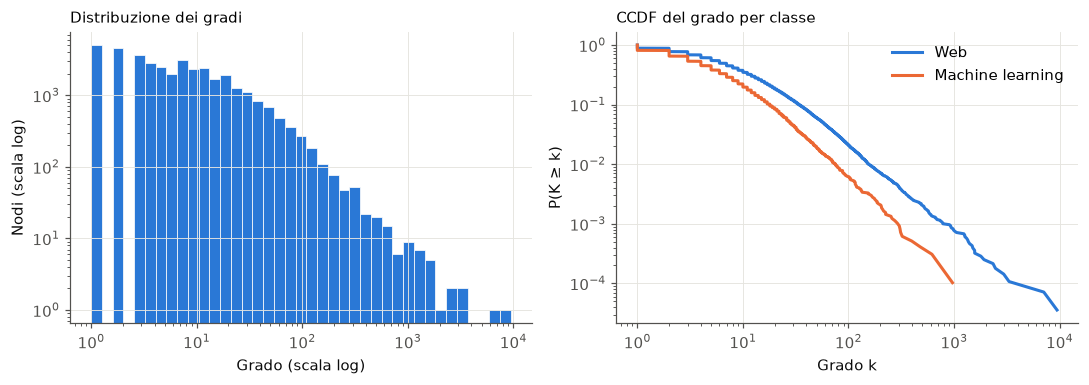

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

ax = axes[0]
ax.hist(deg, bins=np.logspace(0, np.log10(deg.max() + 1), 40), color=WEB_COL,
        edgecolor="#fcfcfb", linewidth=0.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Grado (scala log)"); ax.set_ylabel("Nodi (scala log)")
ax.set_title("Distribuzione dei gradi", loc="left", fontsize=10)

ax = axes[1]
for c in (0, 1):
    d = np.sort(deg[cls_s == c].values)
    ccdf = 1 - np.arange(len(d)) / len(d)
    ax.loglog(d, ccdf, lw=2, color=CLASS_COL[c], label=CLASS_NAME[c])
ax.set_xlabel("Grado k"); ax.set_ylabel("P(K ≥ k)")
ax.set_title("CCDF del grado per classe", loc="left", fontsize=10)
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "distribuzione_gradi")
plt.show()

## 7. Omofilia: chi segue chi?

Si confronta il numero di archi web–web, web–ML e ML–ML con quello atteso se gli archi fossero collocati senza tenere conto della classe (a gradi fissati).

In [18]:
lab = nx.get_node_attributes(G, "ml_target")
pairs = pd.Series([tuple(sorted((lab[u], lab[v]))) for u, v in G.edges()]).value_counts()
m = G.number_of_edges()
k_web = deg[cls_s == 0].sum(); k_ml = deg[cls_s == 1].sum(); K = k_web + k_ml
expected = {(0, 0): m * (k_web / K) ** 2, (0, 1): m * 2 * k_web * k_ml / K**2, (1, 1): m * (k_ml / K) ** 2}
mix = pd.DataFrame({
    "osservati": pairs.reindex(list(expected)).fillna(0).astype(int),
    "attesi (grado fisso)": pd.Series(expected).round(0).astype(int),
})
mix["rapporto"] = (mix["osservati"] / mix["attesi (grado fisso)"]).round(2)
mix.index = ["Web–Web", "Web–ML", "ML–ML"]
mix

,osservati,attesi (grado fisso),rapporto
Web–Web,224623,211052,1.06
Web–ML,44696,71838,0.62
ML–ML,19684,6113,3.22


## 8. Sottografi per il seguito del progetto

* `G_web`, `G_ml` : sottografi indotti da ciascuna classe (equivalente dei sottografi "per campionato" del progetto di riferimento).

* `G_core`: `k-core` più profondo con almeno `CORE_MIN_NODES` nodi; abbastanza piccolo da essere disegnato e per i calcoli esatti (betweenness, cliques) dei capitoli 3 e 4.

In [19]:
G_web = G.subgraph([u for u, c in lab.items() if c == 0]).copy()
G_ml = G.subgraph([u for u, c in lab.items() if c == 1]).copy()

core_num = nx.core_number(G)
nx.set_node_attributes(G, core_num, "core_number")
k_max = max(core_num.values())
print("k-core maximal :", k_max)

core_sizes = pd.Series(core_num).value_counts().sort_index(ascending=False).cumsum()
display(core_sizes.head(15).rename_axis("k").to_frame("nœuds dans le k-core"))

CORE_MIN_NODES = 150   # à ajuster après avoir regardé le tableau ci-dessus
k_sel = int(core_sizes[core_sizes >= CORE_MIN_NODES].index.max())
G_core = nx.k_core(G, k=k_sel).copy()
print(f"G_core = {k_sel}-core : {G_core.number_of_nodes()} nœuds, {G_core.number_of_edges()} arêtes")

k-core maximal : 34


,nœuds dans le k-core
k,
34,360
33,479
32,547
31,735
30,915
29,1090
28,1319
27,1512
26,1692


G_core = 34-core : 360 nœuds, 10488 arêtes


In [20]:
rows = [metrics_G,
        graph_metrics(G_web, "G_web"),
        graph_metrics(G_ml, "G_ml"),
        graph_metrics(G_core, f"G_core (k={k_sel})", exact_paths=True)]
metrics = pd.DataFrame(rows).set_index("Grafo")
metrics.round(4).T

G_web: 46.2 s
G_ml: 3.9 s
G_core (k=34): 0.8 s


Grafo,G,G_web,G_ml,G_core (k=34)
Nodi,37700.0000,27961.0000,9739.0000,360.0000
Archi,289003.0000,224623.0000,19684.0000,10488.0000
Densità,0.0004,0.0006,0.0004,0.1623
Grado medio,15.3317,16.0669,4.0423,58.2667
Grado max,9458.0000,8194.0000,482.0000,303.0000
Componenti,1.0000,297.0000,2466.0000,1.0000
Nodi LCC (%),100.0000,98.8985,72.7282,100.0000
Transitività,0.0124,0.0141,0.0338,0.2387
Clustering medio,0.1675,0.1792,0.0719,0.2915
Assortatività grado,-0.0752,-0.0871,-0.0910,-0.1420


In [21]:
# Composition des classes dans chaque graphe
comp = pd.DataFrame({
    name: pd.Series(nx.get_node_attributes(H, "ml_target")).map(CLASS_NAME).value_counts()
    for name, H in [("G", G), ("G_web", G_web), ("G_ml", G_ml), ("G_core", G_core)]
}).fillna(0).astype(int).T
comp["% ML"] = (100 * comp.get("Machine learning", 0) / comp.sum(axis=1)).round(1)
comp

,Machine learning,Web,% ML
G,9739,27961,25.8
G_web,0,27961,0.0
G_ml,9739,0,100.0
G_core,5,355,1.4


Figure enregistrée : grafo_G_core


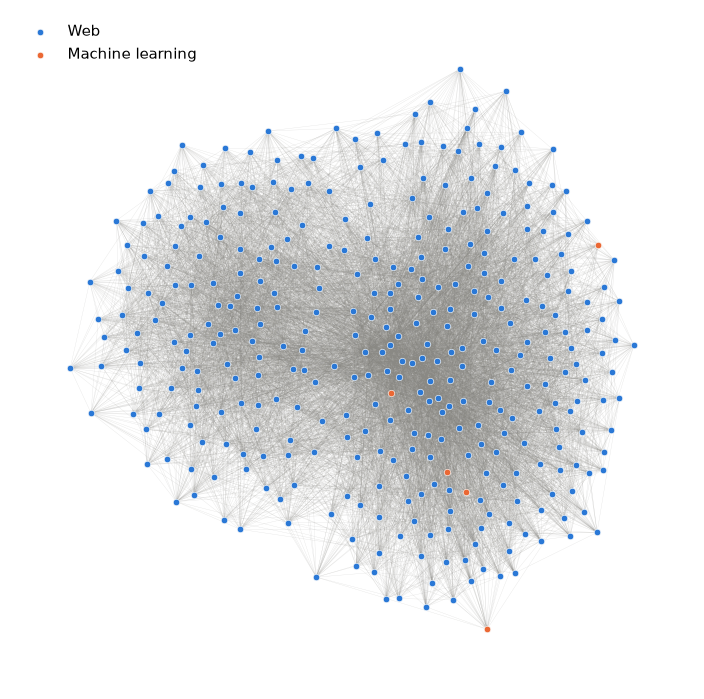

In [22]:
# Dessin de G_core (le graphe complet, 37 700 nœuds, n'est pas lisible)
pos = nx.spring_layout(G_core, seed=SEED, k=1 / np.sqrt(G_core.number_of_nodes()) * 2, iterations=200)
fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_edges(G_core, pos, ax=ax, width=0.2, alpha=0.25, edge_color="#8a8984")
for c in (0, 1):
    nl = [u for u in G_core if lab[u] == c]
    nx.draw_networkx_nodes(G_core, pos, nodelist=nl, ax=ax, node_size=18, node_color=CLASS_COL[c],
                           edgecolors="#fcfcfb", linewidths=0.4, label=CLASS_NAME[c])
ax.legend(frameon=False, loc="upper left")
ax.set_axis_off()
save_fig(fig, "grafo_G_core")
plt.show()

## 9. Salvataggio

In [23]:
nodes = target.set_index("id").copy()
nodes["degree"] = deg
nodes["n_features"] = nfeat
nodes["core_number"] = pd.Series(core_num)
comp_id = {u: i for i, c in enumerate(sorted(nx.connected_components(G), key=len, reverse=True)) for u in c}
nodes["component"] = pd.Series(comp_id)
nodes.to_csv(PROC / "nodes.csv")

for name, H in [("G", G), ("G_web", G_web), ("G_ml", G_ml), ("G_core", G_core)]:
    with open(PROC / f"{name}.pkl", "wb") as f:
        pickle.dump(H, f, protocol=pickle.HIGHEST_PROTOCOL)

# Tableaux LaTeX (booktabs, virgule décimale) à inclure avec \input{}
def fmt_it(x, fmt):
    """Nombre au format italien : 37.700 pour les entiers, 0,0128 pour les décimaux."""
    if isinstance(x, (int, np.integer)) or (isinstance(x, (float, np.floating)) and float(x).is_integer()):
        return f"{int(x):,}".replace(",", ".")
    if isinstance(x, (float, np.floating)):
        return "" if np.isnan(x) else fmt.format(x).replace(".", ",")
    return x

def to_latex(df, name, caption, label, fmt="{:.4f}"):
    out = df.astype(object).apply(lambda col: col.map(lambda x: fmt_it(x, fmt)))
    tex = out.to_latex(caption=caption, label=label, position="H", escape=True,
                       column_format="l" + "r" * out.shape[1])
    tex = tex.replace("\\begin{table}[H]", "\\begin{table}[H]\n\\centering")
    (TAB / f"{name}.tex").write_text(tex, encoding="utf-8")
    print("Tableau enregistré :", name)

to_latex(cmp, "confronto_snap", "Statistiche di G confrontate con quelle dichiarate da SNAP", "tab:confronto_snap")
to_latex(metrics.T, "metriche_grafi", "Metriche dei grafi analizzati", "tab:metriche_grafi")
to_latex(mix, "omofilia", "Archi osservati e attesi per coppia di classi", "tab:omofilia", fmt="{:.2f}")
print("\nFichiers dans", PROC, ":", sorted(p.name for p in PROC.iterdir()))

Tableau enregistré : confronto_snap
Tableau enregistré : metriche_grafi
Tableau enregistré : omofilia

Fichiers dans C:\Users\toyem\Desktop\MAGISTRALE\2° ANNO\DATA SCIENCE\DATA_SCIENCE_PROJECT\2_SOCIAL_NETWORK_ANALYSIS\data\processed : ['G.pkl', 'G_core.pkl', 'G_ml.pkl', 'G_web.pkl', 'nodes.csv']
